# FarmTech Solutions — Modelagem de IA
## Fase 3 · Capítulo 11 · Parte de Gabriel

**Gabriel Tamais Fischer · RM 574503 · FIAP**

Este notebook cobre os cards atribuídos a Gabriel no Trello: preparação
compartilhada para Machine Learning e treinamento/avaliação do Random Forest.
O notebook-base e o nome da entrega final do grupo são responsabilidade da
Bruna; este arquivo foi mantido separado para integração posterior.

**Escopo de integração:** o mesmo split estratificado, pipeline de escala e
validação cruzada deste notebook devem ser reutilizados pelos outros quatro
algoritmos. A comparação final e a escolha do melhor modelo aguardam as métricas
reais de Árvore de Decisão, Regressão Logística, SVM e Gradient Boosting,
atribuídos aos colegas. Nenhum resultado desses modelos é presumido aqui.

### Resumo do experimento executado

No teste estratificado de 440 registros, o Random Forest obteve **Accuracy
0,9955**, **Precision macro 0,9957**, **Recall macro 0,9955** e **F1 macro
0,9955**. Na validação cruzada de cinco folds no treino, as médias foram
Accuracy 0,9932 e F1 macro 0,9931; os desvios padrão foram 0,0059 para ambos.
A diferença de F1 treino-teste foi 0,0045. A variável mais importante por
redução de impureza foi `rainfall` (0,2215). Estes valores descrevem somente
este dataset e este modelo; ainda não estabelecem o vencedor entre cinco
algoritmos.

## 1. Fonte e contrato dos dados

O arquivo utilizado é a cópia byte a byte do CSV oficial em
`cap11/data/Atividade_Cap11_produtos_agricolas.csv`. A cópia mantém o projeto
reproduzível e não altera o original recebido em Downloads.

As entradas são `N`, `P`, `K`, `temperature`, `humidity`, `ph` e `rainfall`; a
variável-alvo de classificação multiclasse é `label`. O CSV apresenta `ph` em
minúsculas, equivalente a `pH` no enunciado.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import cross_validate

raiz_execucao = Path.cwd()
candidatos = [raiz_execucao / "cap11", raiz_execucao]
CAP11_DIR = next(p for p in candidatos if (p / "modelagem.py").is_file())
if str(CAP11_DIR) not in sys.path:
    sys.path.insert(0, str(CAP11_DIR))

from modelagem import (
    FEATURES,
    TARGET,
    RANDOM_STATE,
    EXPECTED_MODELS,
    METRICS,
    carregar_dataset,
    separar_treino_teste,
    construir_pipeline,
    criar_validacao_cruzada,
    criar_tabela_comparacao,
    plotar_comparacao,
    configurar_estilo_graficos,
)

configurar_estilo_graficos()
CAMINHO_CSV = CAP11_DIR / "data" / "Atividade_Cap11_produtos_agricolas.csv"
print(f"Dataset: {CAMINHO_CSV.relative_to(raiz_execucao) if CAMINHO_CSV.is_relative_to(raiz_execucao) else CAMINHO_CSV.name}")

Dataset: data\Atividade_Cap11_produtos_agricolas.csv


### 1.1 Conferência do arquivo oficial

In [2]:
dados = carregar_dataset(CAMINHO_CSV)
print(f"Dimensão: {dados.shape[0]:,} linhas × {dados.shape[1]} colunas")
print("Colunas:", dados.columns.tolist())
print("\nTipos:")
display(dados.dtypes.rename("tipo").to_frame())
print("\nValores ausentes por coluna:")
display(dados.isna().sum().rename("ausentes").to_frame())
print(f"Linhas duplicadas completas: {dados.duplicated().sum()}")
print(f"Quantidade de culturas: {dados[TARGET].nunique()}")
print("\nRegistros por cultura:")
display(dados[TARGET].value_counts().sort_index().rename("registros").to_frame())
display(dados.head())

assert dados.columns.tolist() == FEATURES + [TARGET]
assert TARGET not in FEATURES
assert not dados.empty

Dimensão: 2,200 linhas × 8 colunas
Colunas: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Tipos:


,tipo
N,int64
P,int64
K,int64
temperature,float64
humidity,float64
ph,float64
rainfall,float64
label,str



Valores ausentes por coluna:


,ausentes
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


Linhas duplicadas completas: 0
Quantidade de culturas: 22

Registros por cultura:


,registros
label,
apple,100
banana,100
blackgram,100
chickpea,100
coconut,100
coffee,100
cotton,100
grapes,100
jute,100


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


A validação do arquivo confirma o schema esperado e a ausência de
valores ausentes e duplicatas. Não foi necessário remover ou imputar linhas.
A distribuição por cultura é apresentada para confirmar a estratificação do
split; a análise exploratória e descritiva completa pertence ao card do Fabio.

## 2. Preparação compartilhada para Machine Learning

In [3]:
particoes = separar_treino_teste(dados, random_state=RANDOM_STATE)
X_train, X_test = particoes.X_train, particoes.X_test
y_train, y_test = particoes.y_train, particoes.y_test

print(f"Treino: {X_train.shape[0]:,} registros")
print(f"Teste:  {X_test.shape[0]:,} registros")
print(f"Features: {X_train.columns.tolist()}")
print(f"Target incluído em X? {TARGET in X_train.columns}")
print(f"Índices de treino/teste sobrepostos? {bool(set(X_train.index) & set(X_test.index))}")
display(pd.concat(
    [y_train.value_counts(normalize=True), y_test.value_counts(normalize=True)],
    axis=1,
    keys=["treino", "teste"],
).sort_index().head(10).style.format("{:.3f}"))

assert TARGET not in X_train.columns
assert list(X_train.columns) == FEATURES
assert len(X_test) == len(y_test)
assert not (set(X_train.index) & set(X_test.index))
assert set(y_train.unique()) == set(dados[TARGET].unique())
assert set(y_test.unique()) == set(dados[TARGET].unique())

Treino: 1,760 registros
Teste:  440 registros
Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Target incluído em X? False
Índices de treino/teste sobrepostos? False


,treino,teste
label,,
apple,0.045,0.045
banana,0.045,0.045
blackgram,0.045,0.045
chickpea,0.045,0.045
coconut,0.045,0.045
coffee,0.045,0.045
cotton,0.045,0.045
grapes,0.045,0.045
jute,0.045,0.045


O split é estratificado, usa 20% dos registros como teste e fixa
`random_state=42`. O conjunto de teste fica separado para a avaliação final.
`StandardScaler` está dentro do Pipeline: seu ajuste ocorre apenas nos dados de
treino e é repetido dentro de cada fold da validação cruzada. Nenhuma
transformação é ajustada sobre o teste.

## 3. Random Forest — validação cruzada

In [4]:
modelo_rf = construir_pipeline(
    RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )
)

cv = criar_validacao_cruzada()
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
}
resultado_cv = cross_validate(
    modelo_rf,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=1,
)

resumo_cv = pd.DataFrame(
    {
        "média": [resultado_cv[f"test_{metrica}"].mean() for metrica in METRICS],
        "desvio padrão": [resultado_cv[f"test_{metrica}"].std(ddof=1) for metrica in METRICS],
    },
    index=METRICS,
)
display(resumo_cv.style.format("{:.4f}"))

,média,desvio padrão
accuracy,0.9932,0.0059
precision_macro,0.9939,0.0050
recall_macro,0.9932,0.0059
f1_macro,0.9931,0.0059


A validação cruzada usa cinco folds estratificados somente dentro do
conjunto de treino. O splitter compartilhado em `modelagem.py` permite aos
colegas avaliar seus algoritmos com os mesmos folds. Os resultados desta tabela
são médias e desvios entre folds, não uma segunda avaliação do conjunto de
teste.

## 4. Ajuste final e métricas no teste

In [5]:
modelo_rf.fit(X_train, y_train)
predicoes_teste = modelo_rf.predict(X_test)
predicoes_treino = modelo_rf.predict(X_train)

def calcular_metricas(y_verdadeiro, y_previsto):
    return {
        "accuracy": accuracy_score(y_verdadeiro, y_previsto),
        "precision_macro": precision_score(y_verdadeiro, y_previsto, average="macro", zero_division=0),
        "recall_macro": recall_score(y_verdadeiro, y_previsto, average="macro", zero_division=0),
        "f1_macro": f1_score(y_verdadeiro, y_previsto, average="macro", zero_division=0),
    }

metricas_teste = calcular_metricas(y_test, predicoes_teste)
metricas_treino = calcular_metricas(y_train, predicoes_treino)

tabela_metricas = pd.DataFrame(
    {"treino (referência)": metricas_treino, "teste": metricas_teste}
)
tabela_metricas["diferença treino − teste"] = (
    tabela_metricas["treino (referência)"] - tabela_metricas["teste"]
)
display(tabela_metricas.style.format("{:.4f}"))

assert len(predicoes_teste) == len(y_test)
assert all(0 <= valor <= 1 for valor in metricas_teste.values())
assert all(np.isfinite(valor) for valor in metricas_teste.values())

display(Markdown(
    f"No conjunto de teste, o Random Forest obteve **acurácia {metricas_teste['accuracy']:.4f}**, "
    f"**precisão macro {metricas_teste['precision_macro']:.4f}**, "
    f"**recall macro {metricas_teste['recall_macro']:.4f}** e "
    f"**F1 macro {metricas_teste['f1_macro']:.4f}**. "
    f"A diferença entre o F1 de treino e de teste foi "
    f"{tabela_metricas.loc['f1_macro', 'diferença treino − teste']:.4f}; "
    "ela é um sinal descritivo de generalização, não um teste formal de overfitting."
))

,treino (referência),teste,diferença treino − teste
accuracy,1.0000,0.9955,0.0045
precision_macro,1.0000,0.9957,0.0043
recall_macro,1.0000,0.9955,0.0045
f1_macro,1.0000,0.9955,0.0045


No conjunto de teste, o Random Forest obteve **acurácia 0.9955**, **precisão macro 0.9957**, **recall macro 0.9955** e **F1 macro 0.9955**. A diferença entre o F1 de treino e de teste foi 0.0045; ela é um sinal descritivo de generalização, não um teste formal de overfitting.

## 5. Matriz de confusão

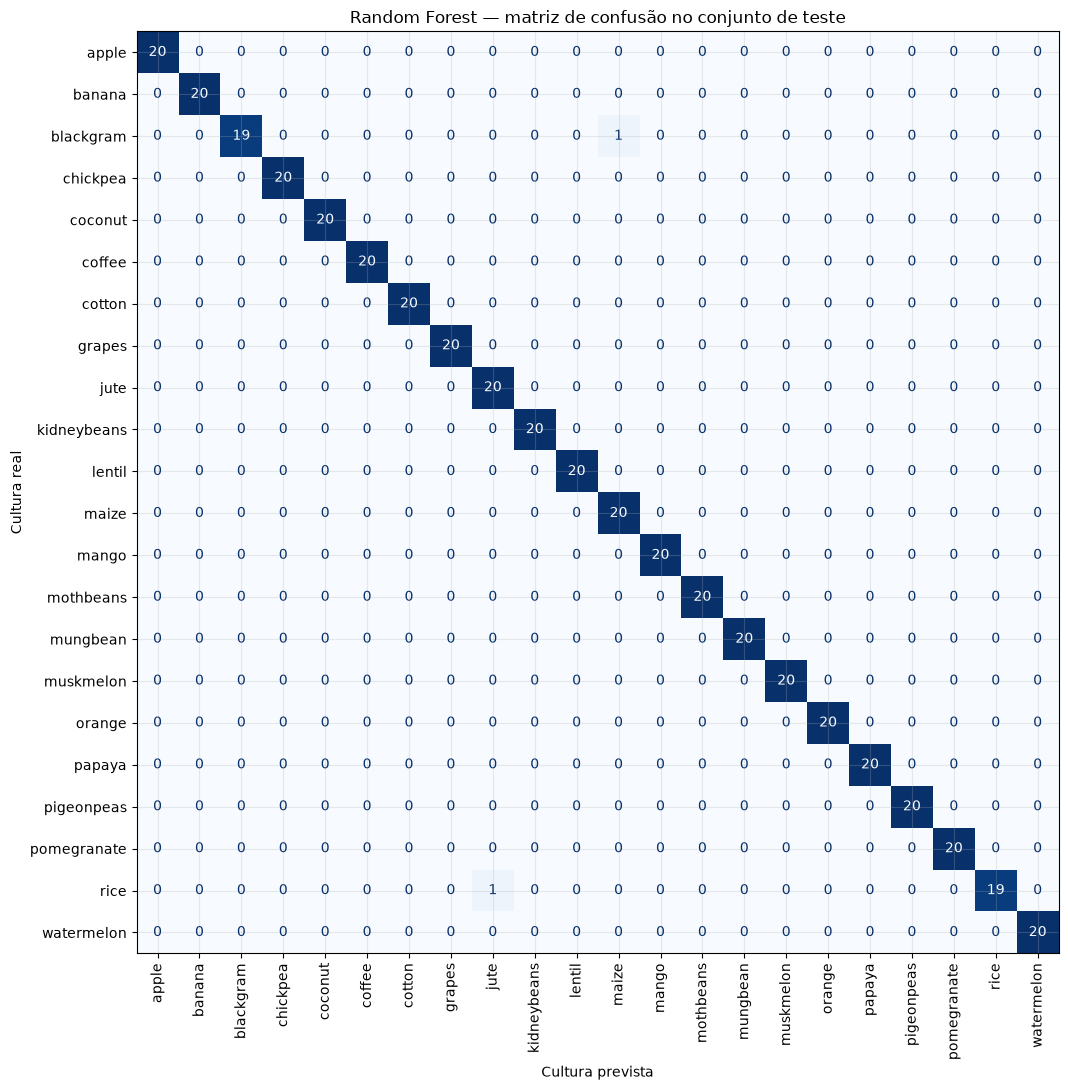

,erros
blackgram,1
rice,1


In [6]:
ordem_classes = sorted(dados[TARGET].unique())
matriz_confusao = confusion_matrix(y_test, predicoes_teste, labels=ordem_classes)
fig, ax = plt.subplots(figsize=(13, 11))
ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusao,
    display_labels=ordem_classes,
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d", xticks_rotation=90)
ax.set_title("Random Forest — matriz de confusão no conjunto de teste")
ax.set_xlabel("Cultura prevista")
ax.set_ylabel("Cultura real")
fig.tight_layout()
plt.show()

erros_por_classe = pd.Series(
    matriz_confusao.sum(axis=1) - matriz_confusao.diagonal(),
    index=ordem_classes,
    name="erros",
).sort_values(ascending=False)
display(erros_por_classe[erros_por_classe > 0].to_frame().head(10))

In [7]:
pares_confusao = [
    {
        "cultura real": ordem_classes[i],
        "prevista como": ordem_classes[j],
        "registros": int(matriz_confusao[i, j]),
    }
    for i in range(len(ordem_classes))
    for j in range(len(ordem_classes))
    if i != j and matriz_confusao[i, j] > 0
]
tabela_confusoes = pd.DataFrame(pares_confusao)
if not tabela_confusoes.empty:
    tabela_confusoes = tabela_confusoes.sort_values(
        "registros", ascending=False, kind="stable"
    ).reset_index(drop=True)
display(tabela_confusoes.head(10))

,cultura real,prevista como,registros
0,blackgram,maize,1
1,rice,jute,1


As células fora da diagonal representam previsões incorretas. As
tabelas identificam tanto classes com maior número absoluto de erros quanto os
pares de culturas mais frequentemente confundidos. Cada contagem deve ser lida
junto ao suporte da classe no teste.

## 6. Importância das variáveis

,importância
rainfall,0.2215
humidity,0.2119
K,0.1792
P,0.1537
N,0.1039
temperature,0.0758
ph,0.0539


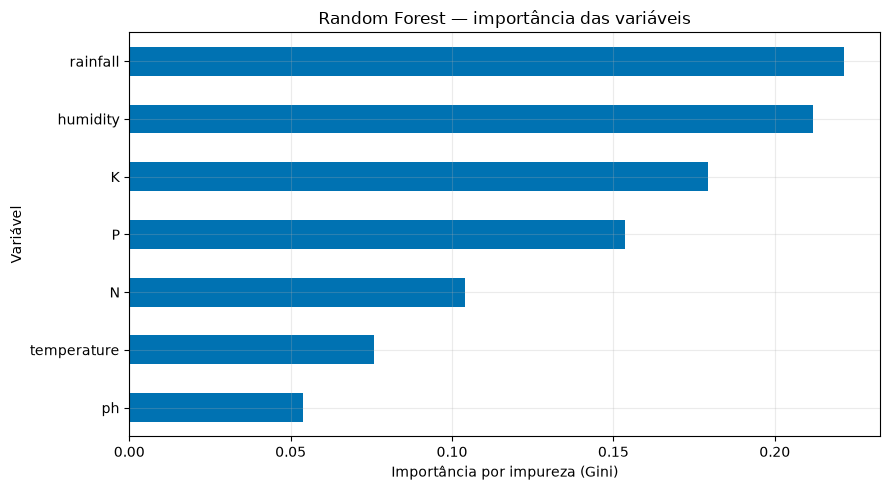

No Random Forest, a variável com maior importância por redução de impureza foi **rainfall** (0.2215). Essa importância descreve o uso da variável neste modelo e não demonstra causalidade.

In [8]:
importancias = pd.Series(
    modelo_rf.named_steps["modelo"].feature_importances_,
    index=FEATURES,
    name="importância",
).sort_values()
display(importancias.sort_values(ascending=False).to_frame().style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(9, 5))
importancias.plot(kind="barh", ax=ax, color="#0072B2")
ax.set_title("Random Forest — importância das variáveis")
ax.set_xlabel("Importância por impureza (Gini)")
ax.set_ylabel("Variável")
fig.tight_layout()
plt.show()

display(Markdown(
    f"No Random Forest, a variável com maior importância por redução de impureza "
    f"foi **{importancias.idxmax()}** ({importancias.max():.4f}). "
    "Essa importância descreve o uso da variável neste modelo e não demonstra causalidade."
))

## 7. Demonstração de previsão com uma linha real do teste

In [9]:
indice_exemplo = X_test.index[0]
linha_exemplo = X_test.loc[[indice_exemplo]]
classe_real = y_test.loc[indice_exemplo]
classe_prevista = modelo_rf.predict(linha_exemplo)[0]
probabilidades = pd.Series(
    modelo_rf.predict_proba(linha_exemplo)[0],
    index=modelo_rf.named_steps["modelo"].classes_,
).sort_values(ascending=False)

print("Índice original da linha de teste:", indice_exemplo)
print("Condições observadas:")
display(linha_exemplo)
print("Cultura real:", classe_real)
print("Cultura prevista:", classe_prevista)
print("Três maiores probabilidades estimadas:")
display(probabilidades.head(3).rename("probabilidade").to_frame().style.format("{:.4f}"))
assert indice_exemplo in X_test.index

Índice original da linha de teste: 1609
Condições observadas:


,N,P,K,temperature,humidity,ph,rainfall
1609,13,23,6,23.961476,90.26408,7.365338,102.69587


Cultura real: orange
Cultura prevista: orange
Três maiores probabilidades estimadas:


,probabilidade
orange,0.9767
pomegranate,0.0233
blackgram,0.0000


## 8. Comparação dos cinco modelos — integração do grupo

In [10]:
# Inclui somente métricas calculadas com os dados reais e o split compartilhado.
resultados_disponiveis = {"Random Forest": metricas_teste}
tabela_comparacao = criar_tabela_comparacao(resultados_disponiveis)
display(tabela_comparacao[METRICS].style.format("{:.4f}"))

modelos_pendentes = tabela_comparacao.attrs["modelos_pendentes"]
print("Modelos aguardando resultados dos colegas:", modelos_pendentes)
if not modelos_pendentes:
    fig = plotar_comparacao(tabela_comparacao)
    plt.show()
else:
    print("Gráfico comparativo final aguardará as métricas reais dos cinco modelos.")

assert set(resultados_disponiveis).issubset(set(EXPECTED_MODELS))
assert "Random Forest" in tabela_comparacao.index

,accuracy,precision_macro,recall_macro,f1_macro
Modelo,,,,
Random Forest,0.9955,0.9957,0.9955,0.9955


Modelos aguardando resultados dos colegas: ['Árvore de Decisão', 'Regressão Logística', 'SVM', 'Gradient Boosting']
Gráfico comparativo final aguardará as métricas reais dos cinco modelos.


A tabela e o gráfico registram o Random Forest já avaliado. A escolha
do algoritmo de melhor desempenho e a comparação final ficam pendentes até a
integração dos resultados reais de Árvore de Decisão, Regressão Logística, SVM
e Gradient Boosting. A função compartilhada não inventa nem completa métricas
ausentes.

## 9. Conclusão da parte de Gabriel

O pipeline oferece uma base reproduzível para avaliação multiclasse: colunas
de entrada explícitas, target separado, split estratificado e fixo,
pré-processamento encapsulado para evitar vazamento e validação cruzada
estratificada. O Random Forest foi ajustado no treino e avaliado uma única vez
no teste reservado, com Accuracy, Precision macro, Recall macro, F1 macro e
matriz de confusão.

O desempenho observado se aplica a este CSV e a esta partição. O modelo não
estabelece causalidade agronômica, não garante desempenho em outras regiões ou
safras e precisa de validação com dados externos antes de qualquer uso
operacional. O ranking dos cinco algoritmos só poderá ser concluído após a
integração dos resultados produzidos pelos colegas.